In [72]:
from google.colab import drive
drive.mount('/content/drive')
!unzip -q "/content/drive/MyDrive/DeepSea/dataset.zip" -d /content/

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
unzip:  cannot find or open /content/drive/MyDrive/DeepSea/dataset.zip, /content/drive/MyDrive/DeepSea/dataset.zip.zip or /content/drive/MyDrive/DeepSea/dataset.zip.ZIP.


In [73]:
import os
print(os.listdir("/content/dataset"))

['dataset']


In [74]:
!nvidia-smi

/bin/bash: line 1: nvidia-smi: command not found


In [75]:
!ls /content/dataset
!ls /content/dataset/datase

dataset
ls: cannot access '/content/dataset/datase': No such file or directory


In [76]:
!find /content/dataset -name "*.json"

Streaming output truncated to the last 5000 lines.
/content/dataset/dataset/original_data/annotations/vid_000133_frame0000010.jpg.json
/content/dataset/dataset/original_data/annotations/vid_000086_frame0000046.jpg.json
/content/dataset/dataset/original_data/annotations/vid_000255_frame0000096.jpg.json
/content/dataset/dataset/original_data/annotations/vid_000075_frame0000059.jpg.json
/content/dataset/dataset/original_data/annotations/vid_000425_frame0000017.jpg.json
/content/dataset/dataset/original_data/annotations/vid_000285_frame0000079.jpg.json
/content/dataset/dataset/original_data/annotations/vid_000262_frame0000014.jpg.json
/content/dataset/dataset/original_data/annotations/vid_000038_frame0000009.jpg.json
/content/dataset/dataset/original_data/annotations/vid_000024_frame0000015.jpg.json
/content/dataset/dataset/original_data/annotations/vid_000433_frame0000016.jpg.json
/content/dataset/dataset/original_data/annotations/vid_000297_frame0000008.jpg.json
/content/dataset/dataset/

In [77]:
import json

chemin = "/content/dataset/dataset/instance_version/instances_train_trashcan.json"
with open(chemin) as f:
    data = json.load(f)

In [78]:
data.keys()

dict_keys(['info', 'licenses', 'images', 'annotations', 'categories'])

In [79]:
len(data["images"])

6065

In [80]:
data["images"][0]

{'id': 1,
 'file_name': 'vid_000159_frame0000008.jpg',
 'width': 480,
 'height': 270}

In [81]:
data["categories"]

[{'supercategory': 'rov', 'id': 1, 'name': 'rov'},
 {'supercategory': 'plant', 'id': 2, 'name': 'plant'},
 {'supercategory': 'animal_fish', 'id': 3, 'name': 'animal_fish'},
 {'supercategory': 'animal_starfish', 'id': 4, 'name': 'animal_starfish'},
 {'supercategory': 'animal_shells', 'id': 5, 'name': 'animal_shells'},
 {'supercategory': 'animal_crab', 'id': 6, 'name': 'animal_crab'},
 {'supercategory': 'animal_eel', 'id': 7, 'name': 'animal_eel'},
 {'supercategory': 'animal_etc', 'id': 8, 'name': 'animal_etc'},
 {'supercategory': 'trash_clothing', 'id': 9, 'name': 'trash_clothing'},
 {'supercategory': 'trash_pipe', 'id': 10, 'name': 'trash_pipe'},
 {'supercategory': 'trash_bottle', 'id': 11, 'name': 'trash_bottle'},
 {'supercategory': 'trash_bag', 'id': 12, 'name': 'trash_bag'},
 {'supercategory': 'trash_snack_wrapper',
  'id': 13,
  'name': 'trash_snack_wrapper'},
 {'supercategory': 'trash_can', 'id': 14, 'name': 'trash_can'},
 {'supercategory': 'trash_cup', 'id': 15, 'name': 'trash_cu

Une annotation, c’est une réponse écrite par un humain

Imagine que tu veux apprendre à un enfant à reconnaître un sac plastique sur une photo. Tu lui montres la photo, tu prends un stylo et tu entoures le sac en disant : « ça, c’est un sac plastique ».

Ce que tu viens de faire, c’est une annotation. Une personne a regardé chaque photo du dataset et a entouré à la main chaque objet (ROV, poisson, déchet...) en notant sa classe.

Ce qu’il y a dans une annotation

Reprenons la première annotation de ton fichier :

Champ	Ce que ça veut dire
image_id: 1	« Sur la photo n°1... »
category_id: 1	« ...il y a un ROV (classe 1)... »
segmentation: [415, 270, 415.9, 263, ...]

In [82]:
data["annotations"][0]

{'segmentation': [[415.0,
   270.9979919678715,
   415.991935483871,
   263.0,
   412.9980392156863,
   257.0,
   409.9970760233918,
   244.0,
   403.99693251533745,
   231.0,
   398.0,
   227.00294117647059,
   369.0,
   227.00196078431372,
   349.0,
   221.00632911392404,
   301.0,
   221.00196078431372,
   292.0,
   218.0121951219512,
   287.0,
   218.00196078431372,
   271.0,
   212.01315789473685,
   264.0,
   212.002,
   259.0,
   207.00602409638554,
   254.0,
   208.00462962962962,
   246.01,
   218.0,
   245.00196078431372,
   229.0,
   240.00282485875707,
   239.0,
   240.00196078431372,
   258.0,
   236.0025,
   268.0,
   237.0,
   270.998031496063,
   415.0,
   270.9979919678715]],
 'area': 8547.593678816356,
 'iscrowd': 0,
 'image_id': 1,
 'bbox': [236.0025, 207.00602409638554, 179.98943548387098, 63.99200739967745],
 'category_id': 1,
 'id': 1}

Annotation (liste de points)  →  Masque (tableau de 0 et de 1)                                                    Annotation = le contour d’un objet dessiné par un humain. Masque = la même information transformée en pixels 0/1, pour que le modèle puisse apprendre avec.

In [83]:
id_vers_nom = {c["id"]: c["name"] for c in data["categories"]}
id_vers_nom

{1: 'rov',
 2: 'plant',
 3: 'animal_fish',
 4: 'animal_starfish',
 5: 'animal_shells',
 6: 'animal_crab',
 7: 'animal_eel',
 8: 'animal_etc',
 9: 'trash_clothing',
 10: 'trash_pipe',
 11: 'trash_bottle',
 12: 'trash_bag',
 13: 'trash_snack_wrapper',
 14: 'trash_can',
 15: 'trash_cup',
 16: 'trash_container',
 17: 'trash_unknown_instance',
 18: 'trash_branch',
 19: 'trash_wreckage',
 20: 'trash_tarp',
 21: 'trash_rope',
 22: 'trash_net'}

In [84]:
ids_dechets = [i for i, nom in id_vers_nom.items() if nom.startswith("trash_")]
print(len(ids_dechets))
print(ids_dechets)

14
[9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]


rov 2633 veut dire 2633 annotations de ROV, pas 2633 images.

In [85]:
from collections import Counter

compteur = Counter(id_vers_nom[a["category_id"]] for a in data["annotations"])
for nom, n in compteur.most_common():
    print(nom, n)

rov 2633
trash_unknown_instance 2203
trash_bag 727
animal_fish 611
trash_container 407
plant 405
trash_can 366
trash_branch 268
animal_starfish 262
animal_eel 259
animal_crab 246
animal_shells 188
animal_etc 170
trash_wreckage 130
trash_pipe 114
trash_bottle 100
trash_net 94
trash_tarp 90
trash_rope 88
trash_snack_wrapper 67
trash_clothing 65
trash_cup 47


In [86]:
import re

videos = {re.search(r"(vid_\d+)", img["file_name"]).group(1) for img in data["images"]}
print("Vidéos dans le train :", len(videos))

Vidéos dans le train : 310


310 vidéos. Les 6065 images sont des frames extraites de 310 vidéos, donc plusieurs images viennent de la même vidéo

Étape 5 : construire un masque pour une image

In [87]:
from pycocotools.coco import COCO
import numpy as np
coco = COCO(chemin)

loading annotations into memory...
Done (t=0.40s)
creating index...
index created!


cherche la première annotation dont la classe est un déchet. Résultat : image 2, trash_bag.

In [88]:
ann= next(a for a in data["annotations"]if a ["category_id"] in ids_dechets)
img_id=ann["image_id"]
print(img_id,id_vers_nom[ann["category_id"]])

2 trash_bag


In [89]:
info=coco.imgs[img_id]
mask=np.zeros((info["height"],info["width"]),dtype=np.uint8)
ann_ids=coco.getAnnIds(imgIds=img_id , catIds= ids_dechets, iscrowd=None)
for a in coco.loadAnns(ann_ids):
    mask = np.maximum(mask, coco.annToMask(a))
print(mask.shape,np.unique(mask),mask.sum())


(270, 480) [0 1] 599


mask.sum() → 599 : le nombre de pixels de déchet
np.unique(mask) → [0 1] : les valeurs présentes
mask.shape → (270, 480) : la taille

la vérification visuelle

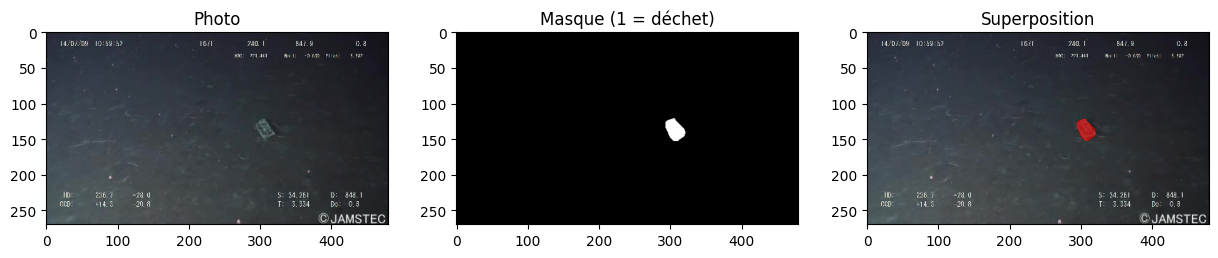

In [90]:
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

racine = "dataset/dataset/instance_version/train/"
photo = Image.open(racine + info["file_name"])

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(photo);                  ax[0].set_title("Photo")
ax[1].imshow(mask, cmap="gray");      ax[1].set_title("Masque (1 = déchet)")
ax[2].imshow(photo)
ax[2].imshow(np.ma.masked_where(mask == 0, mask), alpha=0.6, cmap="autumn")
ax[2].set_title("Superposition")
plt.show()

une fonction de masque réutilisable

In [91]:
def construire_masque(img_id):
    info = coco.imgs[img_id]
    mask = np.zeros((info["height"], info["width"]), dtype=np.uint8)
    ann_ids = coco.getAnnIds(imgIds=img_id)
    for ann in coco.loadAnns(ann_ids):
        nom_classe = coco.cats[ann["category_id"]]["name"]
        if nom_classe.startswith("trash_"):
            mask = np.maximum(mask, coco.annToMask(ann))
    return info, mask

trouver un exemple de chaque cas

In [92]:
# images contenant un ROV, un animal, ou aucun déchet
cas = {"rov": None, "animal": None, "sans_dechet": None}

for img_id in coco.imgs:
    noms = [coco.cats[a["category_id"]]["name"]
            for a in coco.loadAnns(coco.getAnnIds(imgIds=img_id))]
    a_dechet = any(n.startswith("trash_") for n in noms)

    if cas["rov"] is None and "rov" in noms and not a_dechet:
        cas["rov"] = img_id
    if cas["animal"] is None and any(n.startswith("animal_") for n in noms) and not a_dechet:
        cas["animal"] = img_id
    if cas["sans_dechet"] is None and len(noms) > 0 and not a_dechet:
        cas["sans_dechet"] = img_id

    if all(v is not None for v in cas.values()):
        break

print(cas)

{'rov': 1, 'animal': 5, 'sans_dechet': 1}


rov 1 pixels déchet = 0
animal 5 pixels déchet = 0
sans_dechet 1 pixels déchet = 0


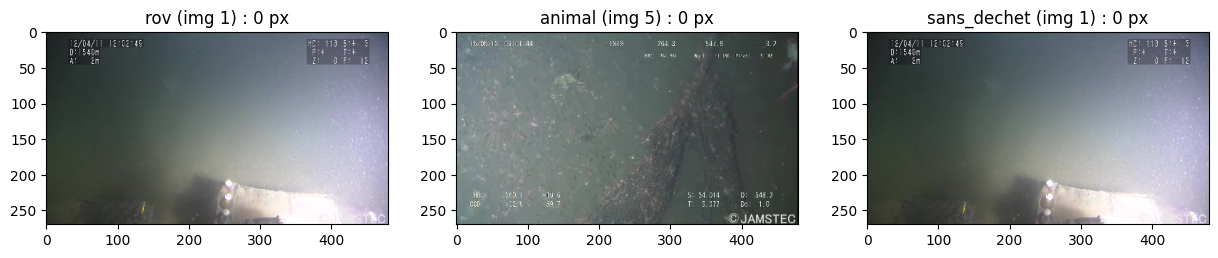

In [93]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

for i, (nom, img_id) in enumerate(cas.items()):
    info, mask = construire_masque(img_id)
    photo = Image.open(racine + info["file_name"])
    ax[i].imshow(photo)
    ax[i].imshow(np.ma.masked_where(mask == 0, mask), alpha=0.6, cmap="autumn")
    ax[i].set_title(f"{nom} (img {img_id}) : {mask.sum()} px")
    print(nom, img_id, "pixels déchet =", mask.sum())

plt.show()

statistiques sur tout le train

In [94]:
import pandas as pd

lignes = []
for img_id in coco.imgs:
    info, mask = construire_masque(img_id)
    lignes.append({
        "img_id": img_id,
        "file_name": info["file_name"],
        "pixels_dechet": int(mask.sum()),
        "pixels_total": mask.size,
    })

df = pd.DataFrame(lignes)
df["proportion"] = df["pixels_dechet"] / df["pixels_total"]
df["a_dechet"] = df["pixels_dechet"] > 0

print("Nombre d'images :", len(df))
print("Avec déchet :", df["a_dechet"].sum())
print("Sans déchet :", (~df["a_dechet"]).sum())
print("Proportion moyenne de déchet (toutes images) : {:.2%}".format(df["proportion"].mean()))
print("Proportion moyenne (images avec déchet seulement) : {:.2%}".format(df.loc[df["a_dechet"], "proportion"].mean()))
print(df["proportion"].describe())

Nombre d'images : 6065
Avec déchet : 4121
Sans déchet : 1944
Proportion moyenne de déchet (toutes images) : 3.81%
Proportion moyenne (images avec déchet seulement) : 5.60%
count    6065.000000
mean        0.038084
std         0.086825
min         0.000000
25%         0.000000
50%         0.007737
75%         0.028547
max         0.940733
Name: proportion, dtype: float64


img_id                                  5048
file_name        vid_000090_frame0000018.jpg
pixels_dechet                         121919
pixels_total                          129600
proportion                          0.940733
a_dechet                                True
Name: 5047, dtype: object


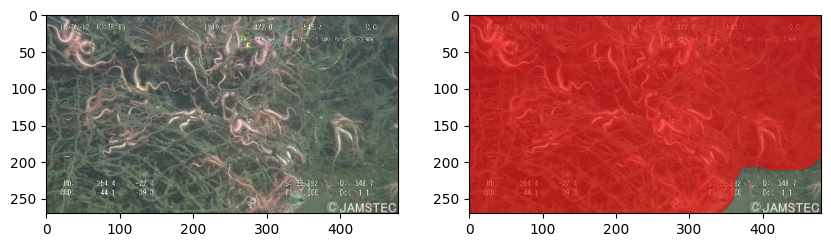

In [95]:
ligne_max = df.loc[df["proportion"].idxmax()]
print(ligne_max)

info, mask = construire_masque(int(ligne_max["img_id"]))
photo = Image.open(racine + info["file_name"])
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(photo)
ax[1].imshow(photo)
ax[1].imshow(np.ma.masked_where(mask == 0, mask), alpha=0.6, cmap="autumn")
plt.show()

ÉTAPE 7 : extraire l'identifiant de vidéo depuis le nom de fichier


## Étape 7 : fusionner train et val officiels, puis extraire la vidéo de chaque image
Le split officiel n'est pas séparé par vidéo (113 des 115 vidéos du val apparaissent aussi dans le train). On fusionne donc les deux fichiers (7 212 images) et on construit un seul tableau, avec la colonne `source` pour retrouver le dossier de chaque image.

Le rôle de l’étape 7 en une phrase : retrouver, pour chaque image, la vidéo dont elle vient, afin de pouvoir ranger toutes les images d’une même vidéo dans le même groupe (train, validation ou test) à l’étape 8.

Cette étape ne change ni les images, ni les masques, ni le modèle : elle ajoute seulement une étiquette de rangement. C’est la condition pour que l’évaluation soit honnête (pas de fuite de données).

In [96]:
import os, numpy as np, pandas as pd
from pycocotools.coco import COCO

base = "dataset/dataset/instance_version/"
print(os.listdir(base))   # vérifier les noms exacts du json val et du dossier val

sources = {
    "train": (base + "instances_train_trashcan.json", base + "train/"),
    "val":   (base + "instances_val_trashcan.json",   base + "val/"),
}
cocos = {s: COCO(chemin) for s, (chemin, _) in sources.items()}
dossiers = {s: dossier for s, (_, dossier) in sources.items()}

['README.txt', 'instances_val_trashcan.json', 'val', 'instances_train_trashcan.json', 'train']
loading annotations into memory...
Done (t=0.72s)
creating index...
index created!
loading annotations into memory...
Done (t=0.16s)
creating index...
index created!


In [97]:
def construire_masque_complet(source, img_id):
    c = cocos[source]
    info = c.imgs[img_id]
    mask = np.zeros((info["height"], info["width"]), dtype=np.uint8)
    for ann in c.loadAnns(c.getAnnIds(imgIds=img_id)):
        if c.cats[ann["category_id"]]["name"].startswith("trash_"):
            mask = np.maximum(mask, c.annToMask(ann))
    return info, mask

In [98]:
lignes = []
for s in sources:
    for img_id in cocos[s].imgs:
        info, mask = construire_masque_complet(s, img_id)
        lignes.append({"source": s, "img_id": img_id,
                       "file_name": info["file_name"],
                       "pixels_dechet": int(mask.sum()),
                       "pixels_total": mask.size})

df = pd.DataFrame(lignes)
df["proportion"] = df["pixels_dechet"] / df["pixels_total"]
df["a_dechet"] = df["pixels_dechet"] > 0
df["video"] = df["file_name"].str.extract(r"(vid_\d+)", expand=False)

assert df["video"].isna().sum() == 0
print(len(df), df["video"].nunique())              # attendu : 7212 312
print(df["source"].value_counts())                 # attendu : train 6065, val 1147
print("Doublons :", df["file_name"].duplicated().sum())   # attendu : 0

7212 312
source
train    6065
val      1147
Name: count, dtype: int64
Doublons : 0


In [99]:
videos = np.array(sorted(df["video"].unique()))
rng = np.random.default_rng(42)      # graine 42 : split reproductible
rng.shuffle(videos)

n = len(videos)
n_train = int(0.70 * n)
n_val = int(0.15 * n)
videos_train = videos[:n_train]
videos_val = videos[n_train:n_train + n_val]
videos_test = videos[n_train + n_val:]
print("Vidéos train/val/test :", len(videos_train), len(videos_val), len(videos_test))

Vidéos train/val/test : 218 46 48


In [100]:
s_train, s_val, s_test = set(videos_train), set(videos_val), set(videos_test)
assert not (s_train & s_val), "Vidéos à la fois dans train et val"
assert not (s_train & s_test), "Vidéos à la fois dans train et test"
assert not (s_val & s_test), "Vidéos à la fois dans val et test"
assert len(s_train) + len(s_val) + len(s_test) == n, "Il manque des vidéos"

groupe_de = {}
for v in videos_train: groupe_de[v] = "train"
for v in videos_val:   groupe_de[v] = "val"
for v in videos_test:  groupe_de[v] = "test"
df["split"] = df["video"].map(groupe_de)
assert df["split"].isna().sum() == 0
print("Aucune fuite : les 3 groupes sont séparés.")

Aucune fuite : les 3 groupes sont séparés.


In [101]:
resume = df.groupby("split").agg(images=("img_id", "count"),
                                 videos=("video", "nunique"))
resume["part_images_%"] = (100 * resume["images"] / len(df)).round(1)
print(resume.loc[["train", "val", "test"]])

equilibre = df.groupby("split").agg(
    part_avec_dechet=("a_dechet", "mean"),
    proportion_moyenne=("proportion", "mean"),
    proportion_mediane=("proportion", "median"),
).loc[["train", "val", "test"]]
print(equilibre.round(4))

       images  videos  part_images_%
split                               
train    5203     218           72.1
val       995      46           13.8
test     1014      48           14.1
       part_avec_dechet  proportion_moyenne  proportion_mediane
split                                                          
train            0.6996              0.0441              0.0089
val              0.7256              0.0303              0.0071
test             0.6903              0.0440              0.0044


In [102]:
df[["source", "img_id", "file_name", "video", "split"]].to_csv("split_liste.csv", index=False)
print(df["split"].value_counts())

split
train    5203
test     1014
val       995
Name: count, dtype: int64


In [103]:
print(len(df), df["video"].nunique())      # attendu : 7212 et 312

print(df["file_name"].duplicated().sum())  # attendu : 0
print(df["split"].value_counts())          # nouveau split sur 7212 images

7212 312
0
split
train    5203
test     1014
val       995
Name: count, dtype: int64
